# Image-level dimensionality reduction (c0 + highdensity_timeconvol)

Flatten microscopy frames into high-dimensional intensity vectors and apply
dimensionality reduction / PCA analysis.

**Channels**
- `data/jpg/c0` — C0 channel (4000 frames, 512×512)
- `data/jpg/highdensity_timeconvol` — time-convolved high-density channel

**Time-series note:** frames are correlated in time. This notebook uses:
1. PCA on **raw** frames (state at each t)
2. PCA on **Δframes** (frame-to-frame change; less autocorrelation)
3. **Subsampled** UMAP/t-SNE for nonlinear structure
4. **Temporal diagnostics** on PC scores (PC vs time, lag-1 autocorrelation)

Images are resized (default 64×64) so all 4000 frames fit in memory.


In [1]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

# Repo root
current_dir = Path.cwd()
repo_root = current_dir.parent if current_dir.name == "analysis" else current_dir
os.chdir(repo_root)

C0_DIR = repo_root / "data" / "jpg" / "c0"
HD_DIR = repo_root / "data" / "jpg" / "highdensity_timeconvol"

RESIZE = (64, 64)          # downsample for tractable PCA (4096-d per frame)
MAX_FRAMES = None          # set e.g. 800 for quick tests; None = all frames
TIME_SUBSAMPLE = 4         # for UMAP/t-SNE (every Nth frame)
DELTA_PCA = True
RANDOM_STATE = 0

sns.set_theme(style="whitegrid")
print("repo:", repo_root)
print("resize:", RESIZE, "->", RESIZE[0]*RESIZE[1], "features/frame")


repo: /Users/svngo/Documents/GitHub/Dicty-Cell-Aggregation-Analysis
resize: (64, 64) -> 4096 features/frame


In [2]:
def frame_index_c0(path: Path) -> int:
    m = re.search(r"_C0_(\d+)", path.name, re.IGNORECASE)
    if not m:
        m = re.search(r"_(\d+)\.jpe?g$", path.name, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def frame_index_hd(path: Path) -> int:
    m = re.search(r"highdensity_timeconvol_(\d+)", path.name, re.IGNORECASE)
    if not m:
        m = re.search(r"_(\d+)\.jpe?g$", path.name, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def list_frames(folder: Path, index_fn) -> list[Path]:
    paths = sorted(folder.glob("*.jpg"), key=index_fn)
    if not paths:
        paths = sorted(folder.glob("*.png"), key=index_fn)
    return paths


def load_vector(path: Path, resize=RESIZE) -> np.ndarray:
    img = Image.open(path).convert("L")
    if resize is not None:
        img = img.resize(resize, Image.Resampling.BILINEAR)
    return np.asarray(img, dtype=np.float32).ravel() / 255.0


def build_matrix(paths: list[Path], resize=RESIZE) -> np.ndarray:
    return np.stack([load_vector(p, resize) for p in tqdm(paths, desc="loading")], axis=0)


def delta_matrix(X: np.ndarray) -> np.ndarray:
    return np.diff(X, axis=0)


c0_paths = list_frames(C0_DIR, frame_index_c0)
hd_paths = list_frames(HD_DIR, frame_index_hd)

if MAX_FRAMES is not None:
    c0_paths = c0_paths[:MAX_FRAMES]
    hd_paths = hd_paths[:MAX_FRAMES]

# Align by frame index (intersection)
c0_map = {frame_index_c0(p): p for p in c0_paths}
hd_map = {frame_index_hd(p): p for p in hd_paths}
common_idx = sorted(set(c0_map) & set(hd_map))
c0_paths_aligned = [c0_map[i] for i in common_idx]
hd_paths_aligned = [hd_map[i] for i in common_idx]

print("c0 frames:", len(c0_paths), "hd frames:", len(hd_paths), "aligned:", len(common_idx))
print("frame index range:", common_idx[0], "->", common_idx[-1])


c0 frames: 4000 hd frames: 4000 aligned: 4000
frame index range: 0 -> 3999


In [3]:
X_c0 = build_matrix(c0_paths_aligned)
X_hd = build_matrix(hd_paths_aligned)
X_joint = np.concatenate([X_c0, X_hd], axis=1)  # both channels per time

t = np.array(common_idx, dtype=float)
print("X_c0", X_c0.shape, "X_hd", X_hd.shape, "X_joint", X_joint.shape)


loading:   0%|          | 0/4000 [00:00<?, ?it/s]

loading:   0%|          | 0/4000 [00:00<?, ?it/s]

X_c0 (4000, 4096) X_hd (4000, 4096) X_joint (4000, 8192)


## 1) PCA on raw intensities (per channel + joint)

We z-score each pixel feature across time, then fit PCA with `svd_solver='randomized'`.


c0 PCA: 12 components, explained var (PC1-3): [0.4404 0.0574 0.0438]
highdensity PCA: 12 components, explained var (PC1-3): [0.4759 0.0773 0.0578]
joint PCA: 12 components, explained var (PC1-3): [0.4567 0.0676 0.0509]


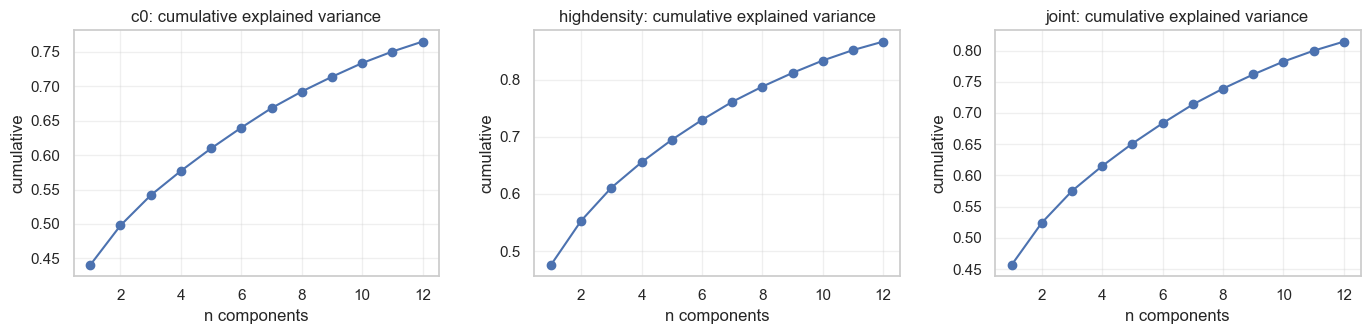

In [4]:
def fit_pca(X: np.ndarray, n_components: int = 10, name: str = "") -> tuple[PCA, np.ndarray, StandardScaler]:
    scaler = StandardScaler()
    Xs = scaler.fit_transform(X)
    n_comp = min(n_components, X.shape[0] - 1, X.shape[1])
    pca = PCA(n_components=n_comp, svd_solver="randomized", random_state=RANDOM_STATE)
    Z = pca.fit_transform(Xs)
    print(f"{name} PCA: {n_comp} components, explained var (PC1-3):", np.round(pca.explained_variance_ratio_[:3], 4))
    return pca, Z, scaler


pca_c0, Z_c0, scaler_c0 = fit_pca(X_c0, n_components=12, name="c0")
pca_hd, Z_hd, scaler_hd = fit_pca(X_hd, n_components=12, name="highdensity")
pca_joint, Z_joint, scaler_joint = fit_pca(X_joint, n_components=12, name="joint")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, pca, title in zip(axes, [pca_c0, pca_hd, pca_joint], ["c0", "highdensity", "joint"]):
    ev = pca.explained_variance_ratio_
    ax.plot(np.arange(1, len(ev)+1), np.cumsum(ev), marker="o")
    ax.set_title(f"{title}: cumulative explained variance")
    ax.set_xlabel("n components")
    ax.set_ylabel("cumulative")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


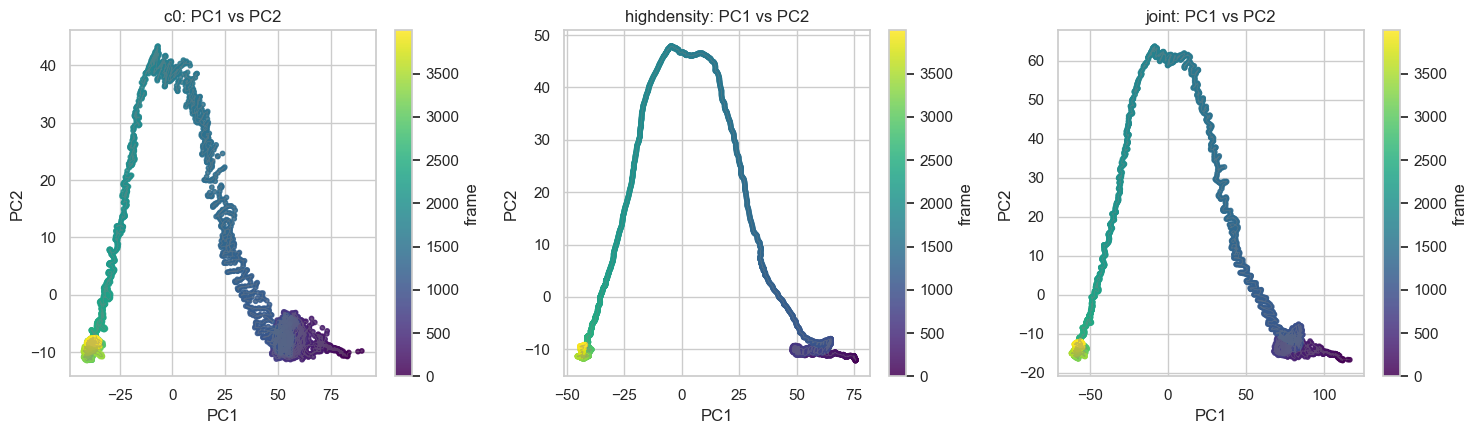

In [5]:
# PC trajectories colored by time
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, Z, title in zip(axes, [Z_c0, Z_hd, Z_joint], ["c0", "highdensity", "joint"]):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=t, cmap="viridis", s=10, alpha=0.85)
    order = np.argsort(t)
    ax.plot(Z[order, 0], Z[order, 1], color="gray", lw=0.6, alpha=0.4)
    ax.set_title(f"{title}: PC1 vs PC2")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    plt.colorbar(sc, ax=ax, label="frame")
plt.tight_layout()
plt.show()


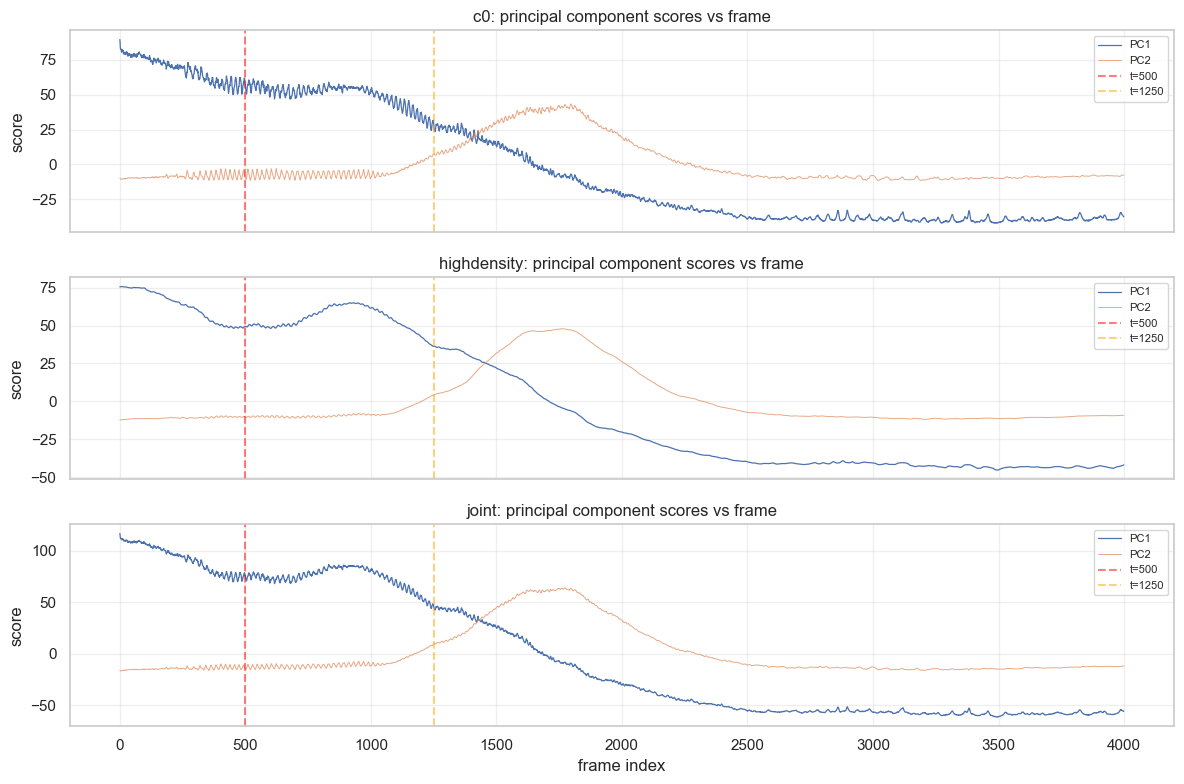

In [6]:
# PC1 vs time (temporal structure)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, Z, title in zip(axes, [Z_c0, Z_hd, Z_joint], ["c0", "highdensity", "joint"]):
    ax.plot(t, Z[:, 0], lw=0.9, label="PC1")
    ax.plot(t, Z[:, 1], lw=0.7, alpha=0.7, label="PC2")
    ax.axvline(500, color="red", ls="--", alpha=0.5, label="t=500")
    ax.axvline(1250, color="orange", ls="--", alpha=0.5, label="t=1250")
    ax.set_ylabel("score")
    ax.set_title(f"{title}: principal component scores vs frame")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("frame index")
plt.tight_layout()
plt.show()


In [7]:
# Lag-1 autocorrelation of PC scores (quantify temporal dependence)
def lag1_autocorr(z: np.ndarray) -> float:
    if len(z) < 2:
        return np.nan
    z = z - z.mean()
    return float(np.corrcoef(z[:-1], z[1:])[0, 1])

rows = []
for name, Z in [("c0", Z_c0), ("highdensity", Z_hd), ("joint", Z_joint)]:
    for k in range(min(5, Z.shape[1])):
        rows.append({"channel": name, "PC": k+1, "lag1_autocorr": lag1_autocorr(Z[:, k])})
ac_df = pd.DataFrame(rows)
print(ac_df.pivot(index="PC", columns="channel", values="lag1_autocorr").round(3))


channel   c0  highdensity  joint
PC                              
1        1.0          1.0    1.0
2        1.0          1.0    1.0
3        1.0          1.0    1.0
4        1.0          1.0    1.0
5        1.0          1.0    1.0


## 2) Eigenimages (PCA loadings reshaped)

Each principal component is a spatial pattern of pixel weights.


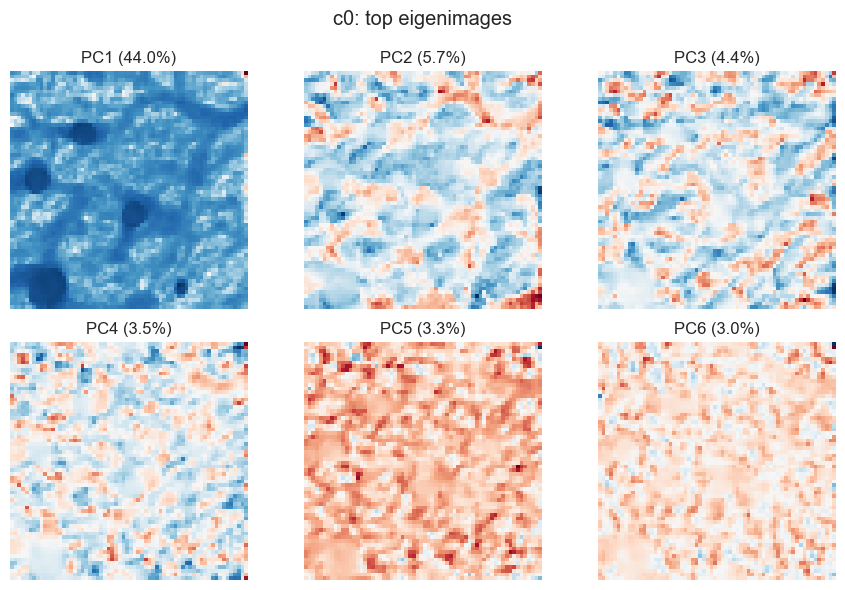

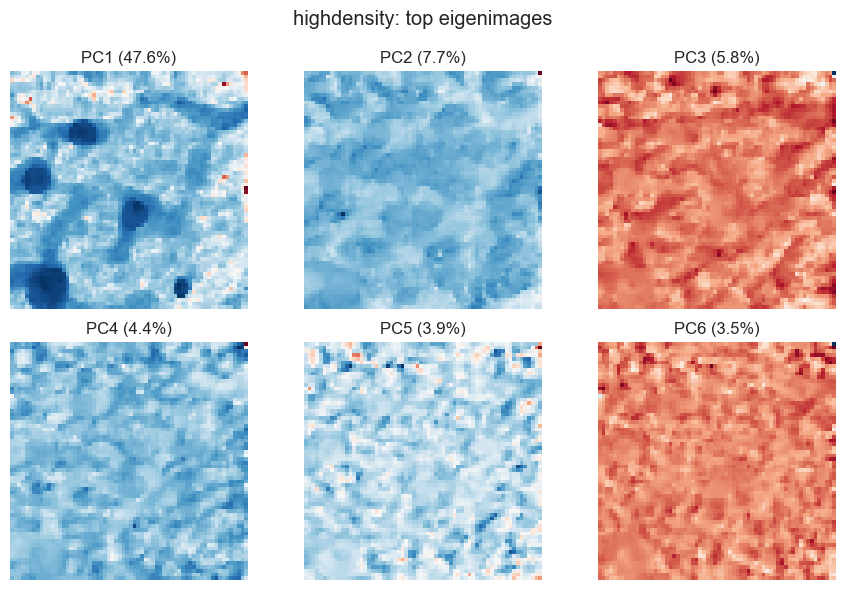

In [8]:
def plot_eigenimages(pca: PCA, scaler: StandardScaler, title: str, n_show: int = 6):
    h, w = RESIZE
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    axes = axes.ravel()
    for i in range(n_show):
        comp = pca.components_[i] / (scaler.scale_ + 1e-8)  # back to pixel space scale
        im = comp.reshape(h, w)
        ax = axes[i]
        ax.imshow(im, cmap="RdBu_r")
        ev = pca.explained_variance_ratio_[i]
        ax.set_title(f"PC{i+1} ({ev*100:.1f}%)")
        ax.axis("off")
    fig.suptitle(f"{title}: top eigenimages")
    plt.tight_layout()
    plt.show()

plot_eigenimages(pca_c0, scaler_c0, "c0")
plot_eigenimages(pca_hd, scaler_hd, "highdensity")


## 3) Δ-frame PCA (time-series aware)

Use consecutive frame differences to emphasize **changes** and reduce slow drift/autocorrelation.


Δc0 PCA: 10 components, explained var (PC1-3): [0.0622 0.0579 0.0427]
Δhighdensity PCA: 10 components, explained var (PC1-3): [0.06   0.0593 0.0356]
Δjoint PCA: 10 components, explained var (PC1-3): [0.056  0.0546 0.037 ]


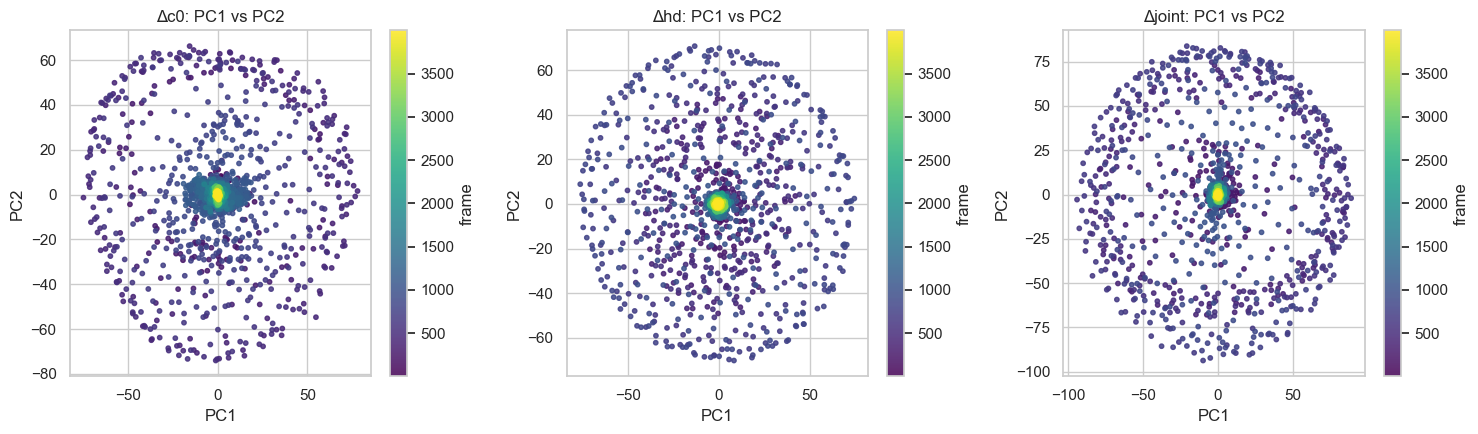

Δ PC lag1 autocorr (PC1):
Δc0 0.9386121713452877
Δhd 0.9481218925283385
Δjoint 0.9465794064329279


In [9]:
if DELTA_PCA:
    d_c0 = delta_matrix(X_c0)
    d_hd = delta_matrix(X_hd)
    d_joint = delta_matrix(X_joint)
    t_delta = t[1:]

    pca_d_c0, Z_d_c0, _ = fit_pca(d_c0, n_components=10, name="Δc0")
    pca_d_hd, Z_d_hd, _ = fit_pca(d_hd, n_components=10, name="Δhighdensity")
    pca_d_joint, Z_d_joint, _ = fit_pca(d_joint, n_components=10, name="Δjoint")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, Z, title in zip(axes, [Z_d_c0, Z_d_hd, Z_d_joint], ["Δc0", "Δhd", "Δjoint"]):
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=t_delta, cmap="viridis", s=10, alpha=0.85)
        ax.set_title(f"{title}: PC1 vs PC2")
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        plt.colorbar(sc, ax=ax, label="frame")
    plt.tight_layout()
    plt.show()

    print("Δ PC lag1 autocorr (PC1):")
    for name, Z in [("Δc0", Z_d_c0), ("Δhd", Z_d_hd), ("Δjoint", Z_d_joint)]:
        print(name, lag1_autocorr(Z[:, 0]))


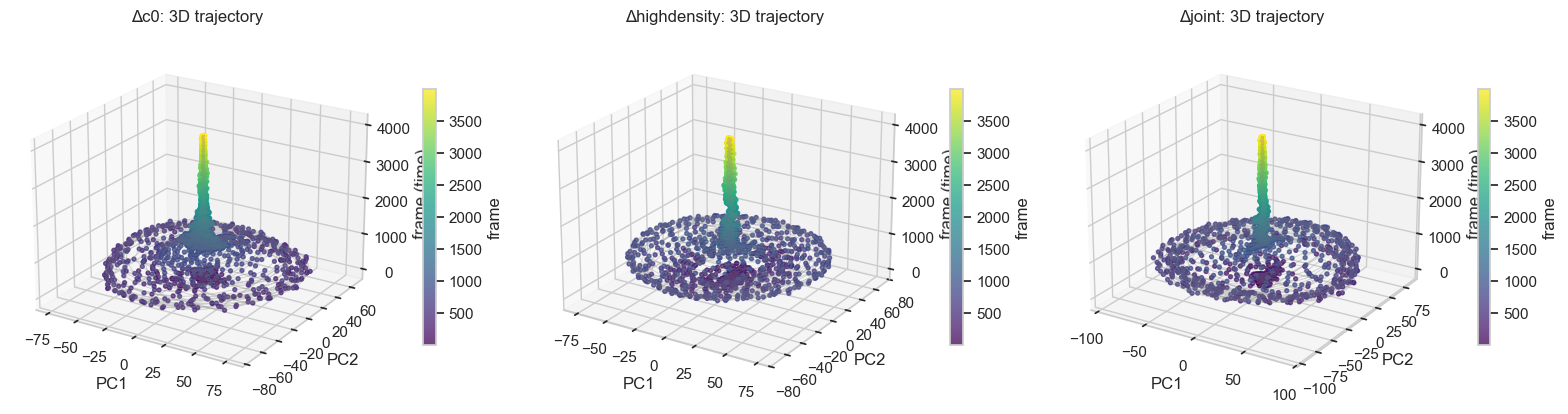

In [14]:
# 3D Δ-frame PCA: PC1 (x), PC2 (y), frame index (z)
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

if DELTA_PCA:
    fig = plt.figure(figsize=(16, 5))
    datasets = [
        (Z_d_c0, "Δc0"),
        (Z_d_hd, "Δhighdensity"),
        (Z_d_joint, "Δjoint"),
    ]

    for i, (Z, title) in enumerate(datasets, start=1):
        ax = fig.add_subplot(1, 3, i, projection="3d")

        # z = time (frame); color also by time for readability
        sc = ax.scatter(
            Z[:, 0],
            Z[:, 1],
            t_delta,
            c=t_delta,
            cmap="viridis",
            s=8,
            alpha=0.75,
            depthshade=True,
        )

        # Connect consecutive frames in time order
        order = np.argsort(t_delta)
        ax.plot(
            Z[order, 0],
            Z[order, 1],
            t_delta[order],
            color="gray",
            lw=0.6,
            alpha=0.35,
        )

        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_zlabel("frame (time)")
        ax.set_title(f"{title}: 3D trajectory")
        ax.view_init(elev=22, azim=-58)
        fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.08, label="frame")

    plt.tight_layout()
    plt.show()


## 4) Nonlinear embeddings (subsampled time)

UMAP / t-SNE on all 4000 full-resolution vectors are expensive and can overfit temporal neighbors.
We subsample every `TIME_SUBSAMPLE` frames for visualization only.


/Users/svngo/Documents/GitHub/Dicty-Cell-Aggregation-Analysis/venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


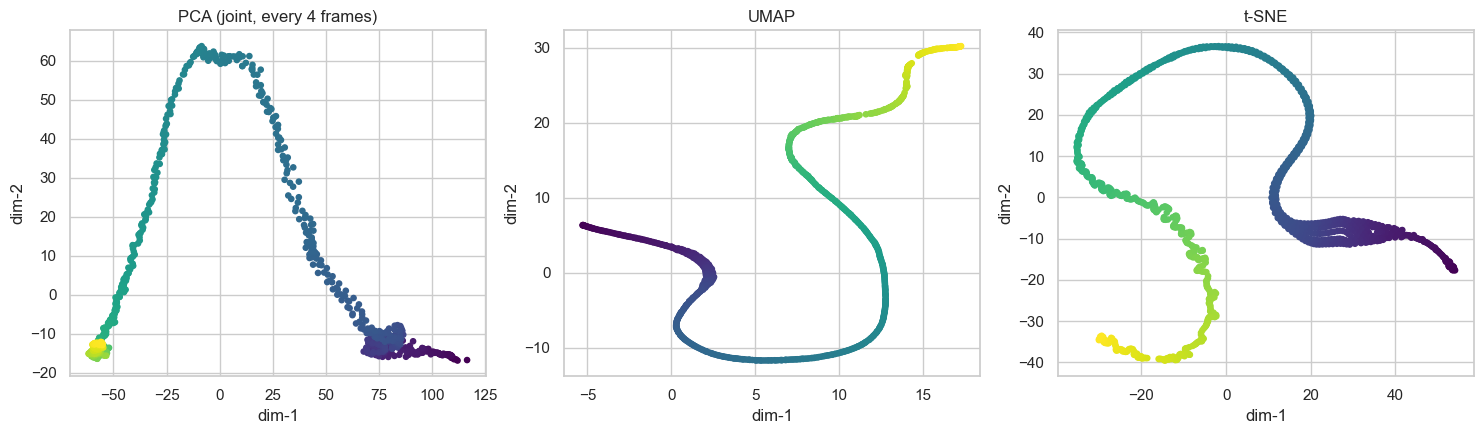

In [11]:
sub_idx = np.arange(0, len(t), TIME_SUBSAMPLE)
Xs = StandardScaler().fit_transform(X_joint[sub_idx])

has_umap = False
has_tsne = False

try:
    import umap
    Z_umap = umap.UMAP(n_components=2, random_state=RANDOM_STATE, n_neighbors=20, min_dist=0.1).fit_transform(Xs)
    has_umap = True
except ImportError:
    Z_umap = None
    print("umap-learn not installed")

from sklearn.manifold import TSNE
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE).fit_transform(Xs)
has_tsne = True

n_panels = 1 + int(has_umap) + int(has_tsne)
fig, axes = plt.subplots(1, n_panels, figsize=(5*n_panels, 4.5))
if n_panels == 1:
    axes = [axes]

Z_pca_sub = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xs)
ts = t[sub_idx]

axes[0].scatter(Z_pca_sub[:,0], Z_pca_sub[:,1], c=ts, cmap="viridis", s=14)
axes[0].set_title(f"PCA (joint, every {TIME_SUBSAMPLE} frames)")

panel = 1
if has_umap:
    axes[panel].scatter(Z_umap[:,0], Z_umap[:,1], c=ts, cmap="viridis", s=14)
    axes[panel].set_title("UMAP")
    panel += 1
if has_tsne:
    axes[panel].scatter(Z_tsne[:,0], Z_tsne[:,1], c=ts, cmap="viridis", s=14)
    axes[panel].set_title("t-SNE")

for ax in axes:
    ax.set_xlabel("dim-1"); ax.set_ylabel("dim-2")
plt.tight_layout()
plt.show()


## 5) Cross-channel comparison at each time

Correlation between PC1 scores from c0 and highdensity (alignment of visual dynamics).


PC1 corr(c0, hd): 0.993021441346738


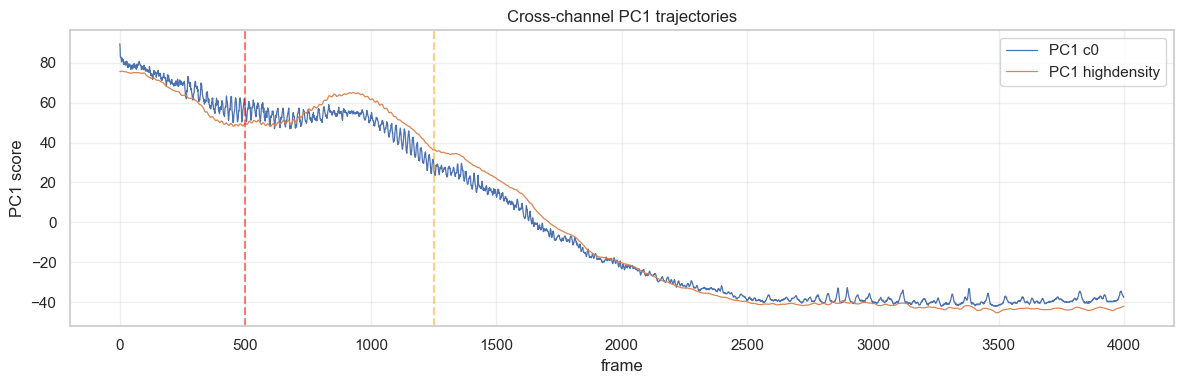

In [12]:
cmp = pd.DataFrame({
    "frame": t,
    "PC1_c0": Z_c0[:, 0],
    "PC1_hd": Z_hd[:, 0],
    "PC1_joint": Z_joint[:, 0],
})
print("PC1 corr(c0, hd):", cmp["PC1_c0"].corr(cmp["PC1_hd"]))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cmp["frame"], cmp["PC1_c0"], label="PC1 c0", lw=0.9)
ax.plot(cmp["frame"], cmp["PC1_hd"], label="PC1 highdensity", lw=0.9)
ax.axvline(500, color="red", ls="--", alpha=0.5)
ax.axvline(1250, color="orange", ls="--", alpha=0.5)
ax.set_xlabel("frame")
ax.set_ylabel("PC1 score")
ax.set_title("Cross-channel PC1 trajectories")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
# Save reduced coordinates for downstream use
out = pd.DataFrame({
    "frame": t,
    **{f"c0_PC{i+1}": Z_c0[:, i] for i in range(Z_c0.shape[1])},
    **{f"hd_PC{i+1}": Z_hd[:, i] for i in range(Z_hd.shape[1])},
    **{f"joint_PC{i+1}": Z_joint[:, i] for i in range(Z_joint.shape[1])},
})
out_path = repo_root / "results" / "trial_5" / "image_pca_scores.csv"
out.to_csv(out_path, index=False)
print("Saved", out_path)


Saved /Users/svngo/Documents/GitHub/Dicty-Cell-Aggregation-Analysis/results/trial_5/image_pca_scores.csv
